### IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Libraries imported successfully!
Pandas: 2.3.2
NumPy: 2.3.3


### LOAD TITANIC DATASET

In [2]:
data_path = Path("data/train.csv")

if not data_path.exists():
    data_path = Path("../data/train.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Không tìm thấy train.csv. "
        "Hãy kiểm tra thư mục data/ trong project."
    )

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (891, 12)

Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### INITIAL DATA EXPLORATION

In [3]:
print("=== MISSING VALUES ===")
display(df.isna().sum().to_frame("Missing values"))

print("\n=== NUMERICAL FEATURES ===")
display(df[["Age", "Fare", "SibSp", "Parch"]].describe())

print("\n=== SURVIVAL DISTRIBUTION ===")
display(df["Survived"].value_counts().to_frame("Passengers"))

=== MISSING VALUES ===


,Missing values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



=== NUMERICAL FEATURES ===


,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000



=== SURVIVAL DISTRIBUTION ===


,Passengers
Survived,
0,549
1,342


### PREPARE DATA FOR NORMALIZATION

In [4]:
norm_df = df[["PassengerId", "Age", "Fare"]].dropna().copy()

print("=== NORMALIZATION DATA ===")
print("Original passengers:", len(df))
print("Valid passengers:", len(norm_df))
print("Excluded rows (missing Age/Fare):", len(df) - len(norm_df))

display(norm_df.head(10))

=== NORMALIZATION DATA ===
Original passengers: 891
Valid passengers: 714
Excluded rows (missing Age/Fare): 177


,PassengerId,Age,Fare
0,1,22.0,7.2500
1,2,38.0,71.2833
2,3,26.0,7.9250
3,4,35.0,53.1000
4,5,35.0,8.0500
6,7,54.0,51.8625
7,8,2.0,21.0750
8,9,27.0,11.1333
9,10,14.0,30.0708
10,11,4.0,16.7000


### NORMALIZATION METHODS

In [5]:
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

features = ["Age", "Fare"]

# Fit and transform for demonstration
norm_df[["Age_MinMax", "Fare_MinMax"]] = (
    minmax_scaler.fit_transform(norm_df[features])
)

norm_df[["Age_Zscore", "Fare_Zscore"]] = (
    standard_scaler.fit_transform(norm_df[features])
)

print("=== BEFORE AND AFTER NORMALIZATION ===")

display(
    norm_df[
        [
            "Age", "Age_MinMax", "Age_Zscore",
            "Fare", "Fare_MinMax", "Fare_Zscore"
        ]
    ].head(10).round(3)
)

=== BEFORE AND AFTER NORMALIZATION ===


,Age,Age_MinMax,Age_Zscore,Fare,Fare_MinMax,Fare_Zscore
0,22.0,0.271,-0.530,7.250,0.014,-0.519
1,38.0,0.472,0.572,71.283,0.139,0.692
2,26.0,0.321,-0.255,7.925,0.015,-0.506
3,35.0,0.435,0.365,53.100,0.104,0.348
4,35.0,0.435,0.365,8.050,0.016,-0.504
6,54.0,0.673,1.674,51.862,0.101,0.325
7,2.0,0.020,-1.908,21.075,0.041,-0.258
8,27.0,0.334,-0.186,11.133,0.022,-0.446
9,14.0,0.171,-1.081,30.071,0.059,-0.087
10,4.0,0.045,-1.770,16.700,0.033,-0.340


### VALIDATE NORMALIZATION

In [6]:
summary = pd.DataFrame({
    "Min": norm_df[
        ["Age", "Age_MinMax", "Age_Zscore",
         "Fare", "Fare_MinMax", "Fare_Zscore"]
    ].min(),
    "Max": norm_df[
        ["Age", "Age_MinMax", "Age_Zscore",
         "Fare", "Fare_MinMax", "Fare_Zscore"]
    ].max(),
    "Mean": norm_df[
        ["Age", "Age_MinMax", "Age_Zscore",
         "Fare", "Fare_MinMax", "Fare_Zscore"]
    ].mean(),
    "Std": norm_df[
        ["Age", "Age_MinMax", "Age_Zscore",
         "Fare", "Fare_MinMax", "Fare_Zscore"]
    ].std(ddof=0)
})

display(summary.round(4))

,Min,Max,Mean,Std
Age,0.4200,80.0000,29.6991,14.5163
Age_MinMax,0.0000,1.0000,0.3679,0.1824
Age_Zscore,-2.0170,3.4651,0.0000,1.0000
Fare,0.0000,512.3292,34.6945,52.8819
Fare_MinMax,0.0000,1.0000,0.0677,0.1032
Fare_Zscore,-0.6561,9.0321,-0.0000,1.0000


### VISUALIZE NORMALIZATION

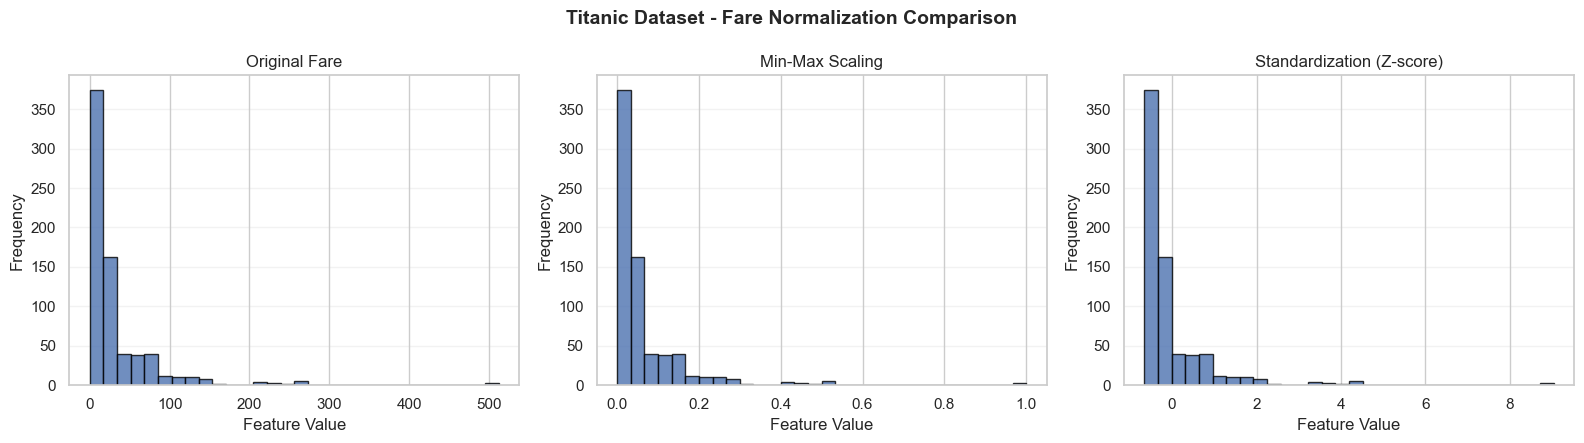

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

columns = [
    ("Fare", "Original Fare"),
    ("Fare_MinMax", "Min-Max Scaling"),
    ("Fare_Zscore", "Standardization (Z-score)")
]

for ax, (column, title) in zip(axes, columns):
    ax.hist(
        norm_df[column],
        bins=30,
        edgecolor="black",
        alpha=0.8
    )
    ax.set_title(title)
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Titanic Dataset - Fare Normalization Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### OUTLIER EFFECT ON MIN-MAX SCALING

In [8]:
fare_values = np.array([10, 20, 30, 40, 50], dtype=float)
fare_with_outlier = np.array([10, 20, 30, 40, 50, 500], dtype=float)

scaler_normal = MinMaxScaler()
scaler_outlier = MinMaxScaler()

scaled_normal = scaler_normal.fit_transform(
    fare_values.reshape(-1, 1)
).ravel()

scaled_outlier = scaler_outlier.fit_transform(
    fare_with_outlier.reshape(-1, 1)
).ravel()

comparison = pd.DataFrame({
    "Original Fare": fare_values,
    "Without Outlier": scaled_normal,
    "With Outlier (500)": scaled_outlier[:5]
})

display(comparison.round(4))

,Original Fare,Without Outlier,With Outlier (500)
0,10.0,0.00,0.0000
1,20.0,0.25,0.0204
2,30.0,0.50,0.0408
3,40.0,0.75,0.0612
4,50.0,1.00,0.0816


### PREPARE DATA FOR DISCRETIZATION

In [9]:
binning_df = df[
    ["PassengerId", "Age", "Survived"]
].dropna(subset=["Age"]).copy()

print("=== AGE DATA ===")
print("Total passengers:", len(df))
print("Passengers with valid Age:", len(binning_df))
print("Missing Age:", df["Age"].isna().sum())

print("\n=== AGE STATISTICS ===")
display(binning_df["Age"].describe().round(2))

display(binning_df.head(10))

=== AGE DATA ===
Total passengers: 891
Passengers with valid Age: 714
Missing Age: 177

=== AGE STATISTICS ===


count    714.00
mean      29.70
std       14.53
min        0.42
25%       20.12
50%       28.00
75%       38.00
max       80.00
Name: Age, dtype: float64

,PassengerId,Age,Survived
0,1,22.0,0
1,2,38.0,1
2,3,26.0,1
3,4,35.0,1
4,5,35.0,0
6,7,54.0,0
7,8,2.0,0
8,9,27.0,1
9,10,14.0,1
10,11,4.0,1


### EQUAL-WIDTH VS EQUAL-FREQUENCY BINNING

In [10]:
num_bins = 4

# Equal-width: 4 khoảng có độ rộng bằng nhau
binning_df["Age_EqualWidth"] = pd.cut(
    binning_df["Age"],
    bins=num_bins,
    include_lowest=True
)

# Equal-frequency: 4 nhóm có số lượng quan sát gần bằng nhau
binning_df["Age_EqualFrequency"] = pd.qcut(
    binning_df["Age"],
    q=num_bins,
    duplicates="raise"
)

print("=== BEFORE AND AFTER DISCRETIZATION ===")

display(
    binning_df[
        ["Age", "Age_EqualWidth", "Age_EqualFrequency"]
    ].head(15)
)

print("\n=== EQUAL-WIDTH COUNTS ===")
print(
    binning_df["Age_EqualWidth"]
    .value_counts()
    .sort_index()
)

print("\n=== EQUAL-FREQUENCY COUNTS ===")
print(
    binning_df["Age_EqualFrequency"]
    .value_counts()
    .sort_index()
)

=== BEFORE AND AFTER DISCRETIZATION ===


,Age,Age_EqualWidth,Age_EqualFrequency
0,22.0,"(20.315, 40.21]","(20.125, 28.0]"
1,38.0,"(20.315, 40.21]","(28.0, 38.0]"
2,26.0,"(20.315, 40.21]","(20.125, 28.0]"
3,35.0,"(20.315, 40.21]","(28.0, 38.0]"
4,35.0,"(20.315, 40.21]","(28.0, 38.0]"
6,54.0,"(40.21, 60.105]","(38.0, 80.0]"
7,2.0,"(0.339, 20.315]","(0.419, 20.125]"
8,27.0,"(20.315, 40.21]","(20.125, 28.0]"
9,14.0,"(0.339, 20.315]","(0.419, 20.125]"
10,4.0,"(0.339, 20.315]","(0.419, 20.125]"



=== EQUAL-WIDTH COUNTS ===
Age_EqualWidth
(0.339, 20.315]    179
(20.315, 40.21]    385
(40.21, 60.105]    128
(60.105, 80.0]      22
Name: count, dtype: int64

=== EQUAL-FREQUENCY COUNTS ===
Age_EqualFrequency
(0.419, 20.125]    179
(20.125, 28.0]     183
(28.0, 38.0]       175
(38.0, 80.0]       177
Name: count, dtype: int64


### COMPARE BIN DISTRIBUTIONS

In [11]:
width_counts = (
    binning_df["Age_EqualWidth"]
    .value_counts()
    .sort_index()
)

frequency_counts = (
    binning_df["Age_EqualFrequency"]
    .value_counts()
    .sort_index()
)

comparison_df = pd.DataFrame({
    "Bin": [f"Bin {i+1}" for i in range(num_bins)],
    "Equal-width Count": width_counts.to_numpy(),
    "Equal-frequency Count": frequency_counts.to_numpy()
})

print("=== BINNING COMPARISON ===")
display(comparison_df)

print("\nTotal Equal-width:", comparison_df["Equal-width Count"].sum())
print("Total Equal-frequency:", comparison_df["Equal-frequency Count"].sum())

=== BINNING COMPARISON ===


,Bin,Equal-width Count,Equal-frequency Count
0,Bin 1,179,179
1,Bin 2,385,183
2,Bin 3,128,175
3,Bin 4,22,177



Total Equal-width: 714
Total Equal-frequency: 714


### VISUALIZE BINNING COMPARISON

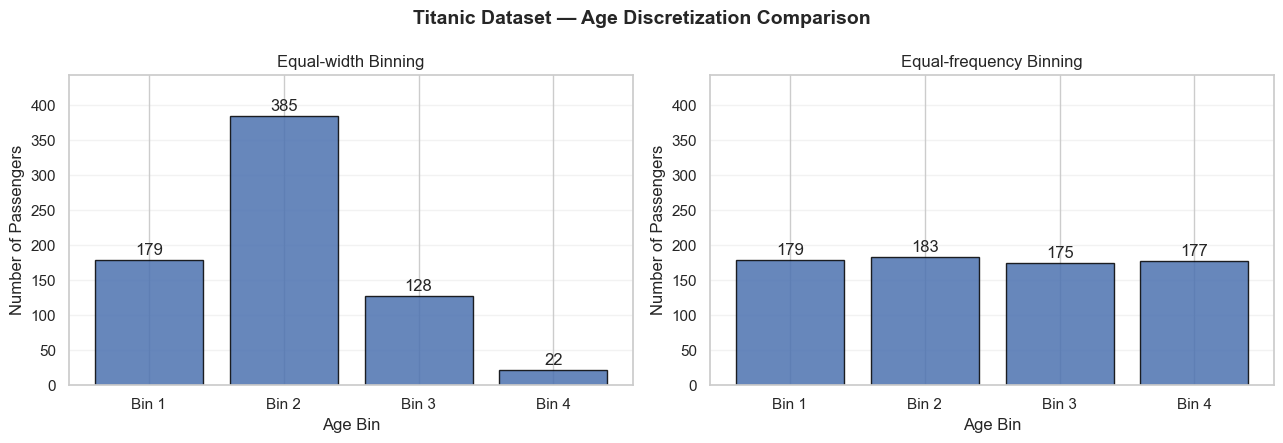

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

methods = [
    ("Equal-width Binning", width_counts),
    ("Equal-frequency Binning", frequency_counts)
]

for ax, (title, counts) in zip(axes, methods):
    bars = ax.bar(
        range(1, len(counts) + 1),
        counts.values,
        edgecolor="black",
        alpha=0.85
    )

    ax.set_title(title)
    ax.set_xlabel("Age Bin")
    ax.set_ylabel("Number of Passengers")
    ax.set_xticks(range(1, len(counts) + 1))
    ax.set_xticklabels(
        [f"Bin {i}" for i in range(1, len(counts) + 1)]
    )
    ax.set_ylim(0, max(width_counts.max(), frequency_counts.max()) * 1.15)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 3,
            str(int(height)),
            ha="center",
            va="bottom"
        )

    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Titanic Dataset — Age Discretization Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### DESCRIPTIVE STATISTICS

In [13]:
fare = df["Fare"].dropna()

fare_stats = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median (Q2)",
        "Standard Deviation",
        "Minimum",
        "Q1 (25%)",
        "Q3 (75%)",
        "Maximum",
        "IQR"
    ],
    "Value": [
        fare.count(),
        fare.mean(),
        fare.median(),
        fare.std(),
        fare.min(),
        fare.quantile(0.25),
        fare.quantile(0.75),
        fare.max(),
        fare.quantile(0.75) - fare.quantile(0.25)
    ]
})

print("=== FARE DESCRIPTIVE STATISTICS ===")
display(fare_stats.round(4))

=== FARE DESCRIPTIVE STATISTICS ===


,Statistic,Value
0,Count,891.0000
1,Mean,32.2042
2,Median (Q2),14.4542
3,Standard Deviation,49.6934
4,Minimum,0.0000
5,Q1 (25%),7.9104
6,Q3 (75%),31.0000
7,Maximum,512.3292
8,IQR,23.0896


### FARE HISTOGRAM

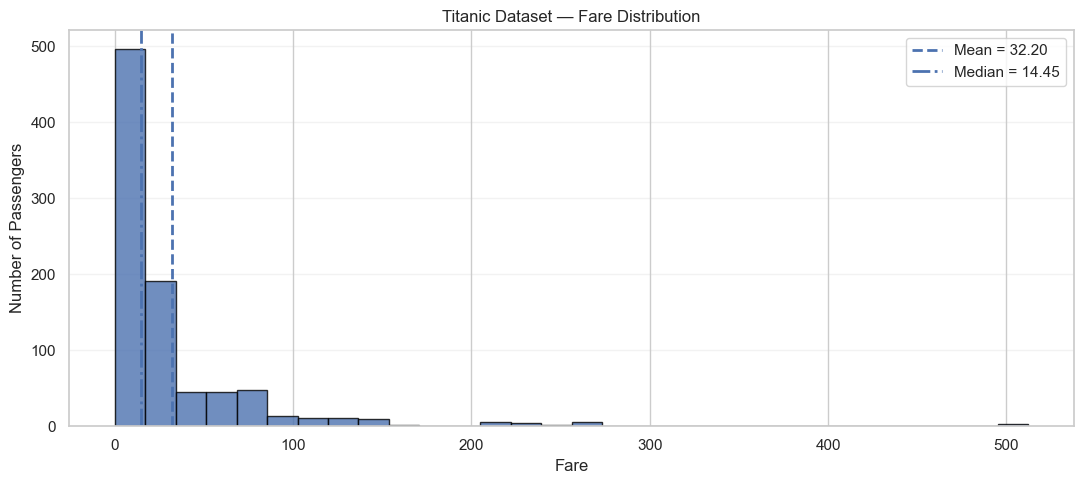

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    fare,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

ax.axvline(
    fare.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {fare.mean():.2f}"
)

ax.axvline(
    fare.median(),
    linestyle="-.",
    linewidth=2,
    label=f"Median = {fare.median():.2f}"
)

ax.set_title("Titanic Dataset — Fare Distribution")
ax.set_xlabel("Fare")
ax.set_ylabel("Number of Passengers")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### GROUPED DESCRIPTIVE STATISTICS

In [15]:
fare_by_class = (
    df.groupby("Pclass")["Fare"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .round(2)
)

print("=== FARE STATISTICS BY PASSENGER CLASS ===")
display(fare_by_class)

=== FARE STATISTICS BY PASSENGER CLASS ===


,Count,Mean,Median,Std,Min,Max
Pclass,,,,,,
1,216,84.15,60.29,78.38,0.0,512.33
2,184,20.66,14.25,13.42,0.0,73.50
3,491,13.68,8.05,11.78,0.0,69.55
